<a href="https://colab.research.google.com/github/ivakhila2007-source/ML-LAB/blob/main/expp%202%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score


In [5]:
url="https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
data=pd.read_csv(url)

In [9]:
data=data[['mpg','displacement']]
data.dropna(inplace=True)

In [10]:
print(data.head())

    mpg  displacement
0  18.0         307.0
1  15.0         350.0
2  18.0         318.0
3  16.0         304.0
4  17.0         302.0


In [12]:
X = data[['displacement']]
y = data['mpg']
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
linear_model=LinearRegression()
linear_model.fit(x_train,y_train)
y_pred_linear=linear_model.predict(x_test)

In [13]:
print("Linear Regression")
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_linear))
print("R-squared:", r2_score(y_test, y_pred_linear))

Linear Regression
Mean Squared Error: 18.102543998358946
R-squared: 0.6633114869465596


In [19]:
degrees=[2,3,4]
for degree in degrees:
  poly = PolynomialFeatures(degree=degree)
  x_train_poly = poly.fit_transform(x_train)
  x_test_poly = poly.transform(x_test)
  model = LinearRegression()
  model.fit(x_train_poly, y_train)
  y_pred_poly = model.predict(x_test_poly)
  print("\nDegree=",degree)
  print("Mean Squared Error:", mean_squared_error(y_test, y_pred_poly))
  print("R-squared:", r2_score(y_test, y_pred_poly))





Degree= 2
Mean Squared Error: 15.10735356108076
R-squared: 0.7190189176110284

Degree= 3
Mean Squared Error: 14.943631793037289
R-squared: 0.722063972418907

Degree= 4
Mean Squared Error: 14.961486893912738
R-squared: 0.7217318860908903


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


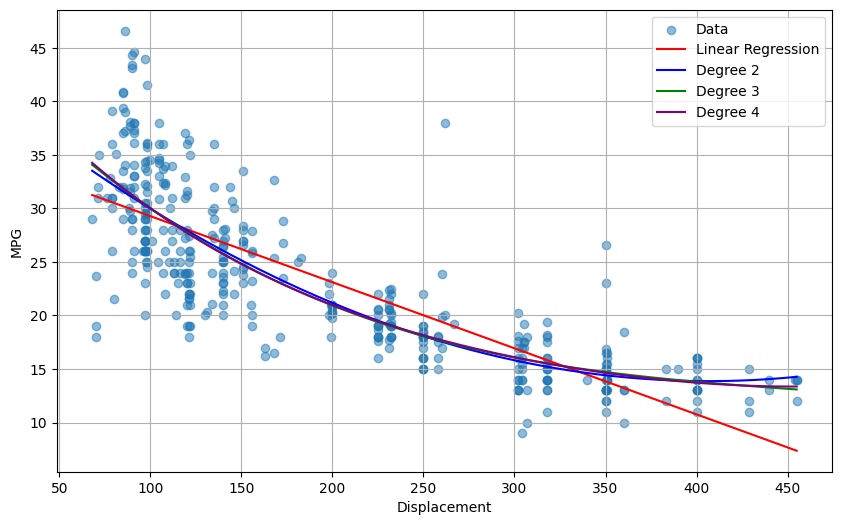

In [24]:
x_range=np.linspace(X.min(),X.max(),300).reshape(-1,1)
plt.figure(figsize=(10,6))
plt.scatter(X,y,alpha=0.5,label= 'Data')
plt.plot(x_range,linear_model.predict(x_range),color='red',label='Linear Regression')
colors=['blue','green','purple']
for degree_val, plot_color in zip([2,3,4],colors):
  poly=PolynomialFeatures(degree=degree_val)
  x_poly=poly.fit_transform(X)
  model=LinearRegression()
  model.fit(x_poly,y)
  plt.plot(x_range,model.predict(poly.transform(x_range)),color=plot_color,label=f'Degree {degree_val}')
plt.xlabel('Displacement')
plt.ylabel('MPG')
plt.legend()
plt.grid()
plt.show()